# 🐍 Clase 42 — Primer clasificador ML

**Curso:** 3ro medio  |  **Duración:** 80 min  |  **Plataforma:** Google Colab

---

## 🎯 Objetivo de la clase

Entrenar un árbol de decisión con datos en listas y usarlo para predecir casos nuevos, con pensamiento crítico.

## 🔎 ¿Por qué lo veremos?

> Cuando una app nos dice «tu micro llegará atrasada», alguien la entrenó con datos de días anteriores, y saber cómo se hace nos permite revisar si su respuesta tiene sentido. Hoy entrenamos un primer modelo con los datos de la micro de La Islita y lo usamos con días nuevos.

---

**Lo que ya sabes:** todo lo dictado hasta N°41 (el mapa de la IA, variables, etiqueta, entrenar ≠ predecir) y Python hasta listas.

**Lo que aprenderás hoy:** crear un `DecisionTreeClassifier`, entrenarlo con `fit()`, predecir con `predict()` y leer sus preguntas con `export_text`. **Todos los datos vienen escritos en este cuaderno** (sin archivos ni descargas) y se ejecuta de arriba hacia abajo.

---

## 1️⃣ Haz Ahora

La junta de vecinos de La Islita quiere un sistema que le avise si la micro de las 7:00 hacia Santiago llegará atrasada, para decidir si salir antes o tomar colectivo. Todavía no sabe qué datos mirar ni cuántos necesita.

1. ¿Qué cosas del día, antes de las 7:00, podrían influir en que la micro se atrase?
2. De esas cosas, ¿cuáles podríamos medir con un número?
3. ¿Qué dato tendríamos que anotar cada día para saber si la micro sí se atrasó?
4. ¿Cuántos días de datos pediríamos, más o menos, antes de confiar en el sistema?

La junta, sabiendo que programamos, nos pide ayuda para armar ese sistema — pero antes quiere que tengamos clara la lógica.

**Mis respuestas:**

1. 
2. 
3. 
4. 

---

### 🔁 Recordemos la clase 41

- **Variables:** lo que el modelo recibe para decidir.
- **Etiqueta:** lo que queremos que el modelo prediga.
- **Entrenar** es aprender de ejemplos; **predecir** es usar lo aprendido en un caso nuevo.

Para la micro de La Islita:

| Dato | Qué es | Ejemplo |
|---|---|---|
| `lluvia_mm` | variable: lluvia de la madrugada | 12 |
| `km_taco` | variable: km de taco en la Ruta 78 a las 6:45 | 6 |
| `pasajeros` | variable: personas esperando en el paradero | 22 |
| etiqueta | `1` = la micro llegó atrasada · `0` = llegó puntual | 1 |

---

## 2️⃣ Introducción al Contenido Nuevo

Estudia cada concepto y escribe tú el código que falta en cada celda, siguiendo la instrucción. Cada celda ya trae **lo que construimos en el concepto anterior**: tú solo agregas lo nuevo.

### 💡 ¿Cómo se ve un árbol de decisión?

Un **árbol de decisión** es una lista de **preguntas de sí/no** encadenadas. Para decidir, se parte desde la pregunta de arriba, se sigue la rama que corresponde a los datos del día y se repite hasta llegar a una **respuesta final**.

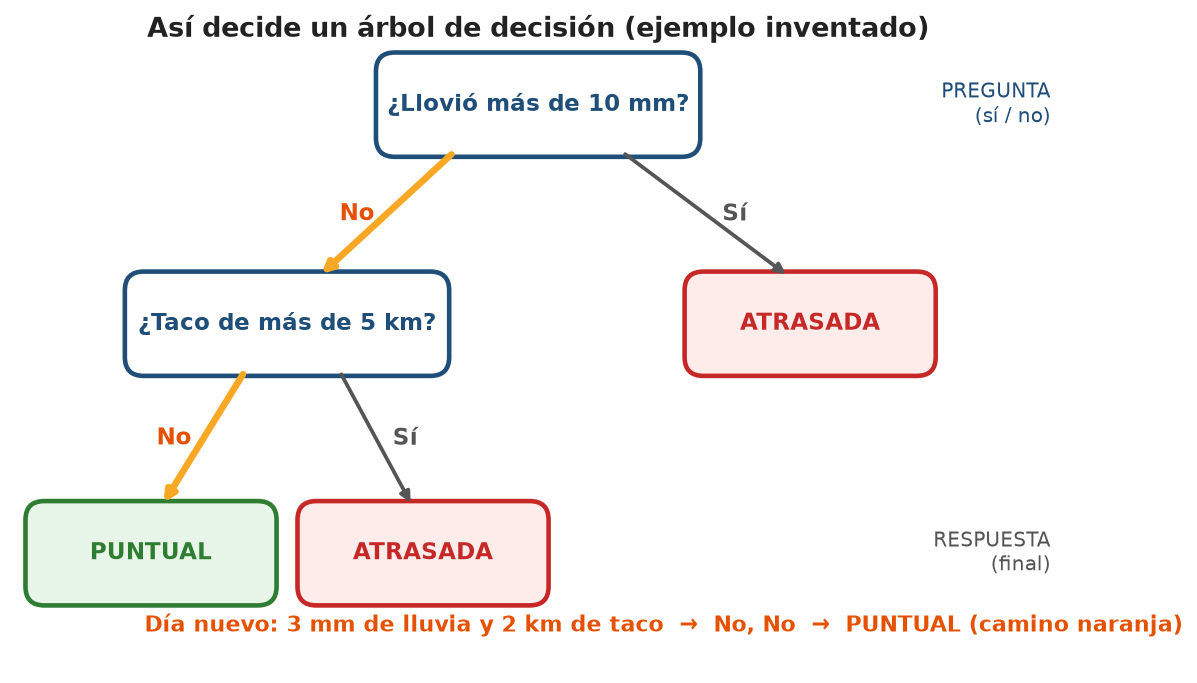

**Cómo leerlo:**

1. Parte siempre desde la pregunta de arriba.
2. Responde «sí» o «no» con los datos de tu día y sigue esa flecha.
3. Si llegas a otra pregunta, vuelve al paso 2; si llegas a una caja de color, esa es la respuesta.

> *Este árbol es un ejemplo inventado, para aprender a leerlo. El árbol de la micro lo va a encontrar el modelo solo, a partir de los datos.*

### 💡 Crear el modelo

Antes de usar un árbol hay que crearlo. Recién creado está vacío: todavía no sabe ninguna pregunta ni ninguna respuesta. Los **16 días** que anotó la junta de vecinos ya vienen escritos: cada día es una lista `[lluvia_mm, km_taco, pasajeros]` y su etiqueta está en la misma posición de `etiquetas`.

> **Idea clave:** El modelo es un árbol de preguntas sí/no; al crearlo todavía no sabe nada.

✍️ **Escríbelo tú:** importa `DecisionTreeClassifier` y crea el modelo con `max_depth=3` y `random_state=0` en una variable llamada `modelo`.

In [ ]:
# Datos de la micro de las 7:00 (ya escritos)
entradas = [[0, 1, 10], [0, 2, 25], [1, 0, 15], [0, 3, 30], [2, 1, 20], [0, 0, 8],
            [12, 6, 22], [15, 8, 30], [8, 7, 12], [20, 9, 18], [10, 2, 28], [18, 5, 9],
            [3, 8, 14], [0, 9, 26], [6, 1, 35], [14, 3, 20]]
etiquetas = [0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1]

### 💡 Entrenar con `fit()`

Entrenar es mostrarle al modelo los días anteriores **con sus etiquetas**, para que descubra qué preguntas separan los días atrasados de los puntuales.

> **Idea clave:** `modelo.fit(entradas, etiquetas)` es entrenar: el árbol busca las preguntas que mejor separan los días atrasados de los puntuales.

✍️ **Escríbelo tú:** entrena el modelo con las entradas y las etiquetas.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Datos de la micro de las 7:00 (ya escritos)
entradas = [[0, 1, 10], [0, 2, 25], [1, 0, 15], [0, 3, 30], [2, 1, 20], [0, 0, 8],
            [12, 6, 22], [15, 8, 30], [8, 7, 12], [20, 9, 18], [10, 2, 28], [18, 5, 9],
            [3, 8, 14], [0, 9, 26], [6, 1, 35], [14, 3, 20]]
etiquetas = [0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1]

modelo = DecisionTreeClassifier(max_depth=3, random_state=0)

### 💡 Predecir con `predict()`

Ahora el modelo ya aprendió. Predecir es preguntarle por un día que **no** estaba en los datos. Como `predict()` trabaja con una lista de días, un solo día va dentro de otra lista.

> **Idea clave:** `modelo.predict([[...]])` es predecir: recibe una lista con los datos de un día nuevo y devuelve 1 (atrasada) o 0 (puntual).

✍️ **Escríbelo tú:** pregunta al modelo por el día nuevo (0 mm de lluvia, 2 km de taco y 12 pasajeros) y muestra el resultado con una etiqueta clara.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Datos de la micro de las 7:00 (ya escritos)
entradas = [[0, 1, 10], [0, 2, 25], [1, 0, 15], [0, 3, 30], [2, 1, 20], [0, 0, 8],
            [12, 6, 22], [15, 8, 30], [8, 7, 12], [20, 9, 18], [10, 2, 28], [18, 5, 9],
            [3, 8, 14], [0, 9, 26], [6, 1, 35], [14, 3, 20]]
etiquetas = [0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1]

modelo = DecisionTreeClassifier(max_depth=3, random_state=0)
modelo.fit(entradas, etiquetas)

dia_nuevo = [0, 2, 12]

#### 🗣️ ¿Quién acierta más? Humano vs. voz vs. modelo

Un día nuevo: **7 mm de lluvia, 4 km de taco y 15 pasajeros**. Antes de preguntarle al modelo:

1. Cada uno decide **a ojo**: ¿atrasada o puntual?
2. Escuchamos qué predice la voz.
3. Recién entonces le preguntamos al modelo y comparamos los tres resultados.

✍️ **Escríbelo tú:** pregunta al modelo por `dia_a_comparar` y muestra el resultado con una etiqueta clara.

✍️ *Mi predicción a ojo:* ...

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Datos de la micro de las 7:00 (ya escritos)
entradas = [[0, 1, 10], [0, 2, 25], [1, 0, 15], [0, 3, 30], [2, 1, 20], [0, 0, 8],
            [12, 6, 22], [15, 8, 30], [8, 7, 12], [20, 9, 18], [10, 2, 28], [18, 5, 9],
            [3, 8, 14], [0, 9, 26], [6, 1, 35], [14, 3, 20]]
etiquetas = [0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1]

modelo = DecisionTreeClassifier(max_depth=3, random_state=0)
modelo.fit(entradas, etiquetas)

dia_nuevo = [0, 2, 12]
prediccion = modelo.predict([dia_nuevo])
print("Predicción para el día nuevo (0 = puntual, 1 = atrasada):", prediccion)

dia_a_comparar = [7, 4, 15]

### 💡 Leer el árbol

El modelo no es una caja cerrada: podemos mirar las preguntas que encontró, igual que en el diagrama del comienzo. Eso nos permite **revisar si tiene sentido**.

> **Idea clave:** `export_text` muestra las preguntas que el árbol encontró: es el **patrón** que descubrió solo.

✍️ **Escríbelo tú:** importa `export_text` y muestra el árbol, indicando los nombres de las variables.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Datos de la micro de las 7:00 (ya escritos)
entradas = [[0, 1, 10], [0, 2, 25], [1, 0, 15], [0, 3, 30], [2, 1, 20], [0, 0, 8],
            [12, 6, 22], [15, 8, 30], [8, 7, 12], [20, 9, 18], [10, 2, 28], [18, 5, 9],
            [3, 8, 14], [0, 9, 26], [6, 1, 35], [14, 3, 20]]
etiquetas = [0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1]

modelo = DecisionTreeClassifier(max_depth=3, random_state=0)
modelo.fit(entradas, etiquetas)

dia_nuevo = [0, 2, 12]
prediccion = modelo.predict([dia_nuevo])
print("Predicción para el día nuevo (0 = puntual, 1 = atrasada):", prediccion)

nombres_variables = ["lluvia_mm", "km_taco", "pasajeros"]

#### 🕵️ Explicar un error

Un día nuevo tiene **5 mm de lluvia, 1 km de taco y 40 pasajeros**, y el árbol predice **puntual**. Escuchamos cómo la voz explica por qué, y **juzgamos entre todos si su explicación cuadra con las preguntas del árbol** que acabamos de leer.

✍️ *¿La explicación cuadra con el árbol? ¿Por qué sí o por qué no?* ...

#### ✅ Verificamos lo aprendido

La voz le pregunta a dos personas del curso:

- ¿Qué diferencia hay entre `fit()` y `predict()`?
- ¿Por qué el árbol ignoró los pasajeros?

### 📌 Entonces, ¿qué debe quedar claro en tu cuaderno?

| Concepto | Ejemplo |
|---|---|
| Crear el modelo | `modelo = DecisionTreeClassifier(max_depth=3, random_state=0)` |
| Entrenar | `modelo.fit(entradas, etiquetas)` |
| Predecir un día nuevo | `modelo.predict([dia_nuevo])` |
| Leer el árbol | `export_text(modelo, feature_names=nombres_variables)` |

---

## 3️⃣ Práctica Guiada

### 🎯 ¿Se atrasará la micro de vuelta?

La junta de vecinos de La Islita ahora quiere saber lo mismo, pero para la micro de las 18:30 que vuelve desde Santiago. Anotó 8 días con la lluvia, los kilómetros de taco en la Autopista del Sol y los minutos que la micro esperó en el terminal antes de salir. Antes de confiar en el sistema, quieren que ustedes revisen si cada respuesta tiene sentido con lo que se vio en los datos.

**El programa debe:**

- **Entrenar** un árbol de decisión con los 8 días (profundidad máxima 3, semilla 0).
- **Predecir** los 3 días nuevos de una sola vez.
- **Mostrar** las predicciones con una etiqueta clara (0 = puntual, 1 = atrasada).
- **Escribir**, en un comentario, una frase por día: ¿esa predicción cuadra con lo que se ve en los datos?

<details><summary>💡 Pista 1 — varios días a la vez</summary>

`predict()` acepta varios días si se los entregas como una lista de listas; justo así viene `dias_nuevos`.

</details>

<details><summary>💡 Pista 2 — para la frase</summary>

Mira en tus datos qué días se parecen al día nuevo y qué etiqueta tenían. Puedes leer el árbol con `export_text`.

</details>

📤 <em>El programa imprime:</em>

<pre>Predicciones de los días nuevos (0 = puntual, 1 = atrasada): [0 1 0]</pre>

In [ ]:
# Tu programa
entradas = [[0, 2, 5], [3, 6, 8], [0, 9, 6], [5, 1, 4], [0, 3, 20], [2, 4, 25], [12, 5, 18], [1, 8, 30]]
etiquetas = [0, 0, 0, 0, 1, 1, 1, 1]
dias_nuevos = [[0, 5, 7], [10, 2, 22], [4, 9, 12]]

# ── Escribe tu programa desde aquí ──

---

## 4️⃣ Práctica Independiente

Resuelve los siguientes ejercicios. Cada uno trae sus propios datos escritos y pistas. Después de cada uno hay un autochequeo que dice ✅ si tu modelo quedó bien entrenado; **busca tu árbol en la variable `modelo`**, así que usa ese nombre.

In [ ]:
#@title 🔧 Verificador automático — ejecuta esta celda antes de empezar (no la edites)
import base64
import hashlib
from sklearn.tree import DecisionTreeClassifier


def _revisar(entradas, etiquetas):
    modelo_alumno = globals().get("modelo")
    if modelo_alumno is None:
        print("⚠️ Todavía no hay un modelo llamado modelo.")
        print("   Pista: crea el árbol y guárdalo en una variable con ese nombre.")
        return
    if not isinstance(modelo_alumno, DecisionTreeClassifier):
        print("⚠️ La variable modelo existe, pero no es un árbol de decisión.")
        print("   Pista: ¿con qué instrucción se crea el árbol?")
        return
    if not hasattr(modelo_alumno, "tree_"):
        print("⚠️ El árbol está creado, pero todavía no aprendió nada.")
        print("   Pista: falta el paso que le entrega los días anteriores y sus etiquetas.")
        return
    if modelo_alumno.n_features_in_ != len(entradas[0]) or modelo_alumno.tree_.n_node_samples[0] != len(entradas):
        print("⚠️ Tu modelo se entrenó con otros datos, no con los de este ejercicio.")
        print("   Pista: revisa qué le entregas al entrenar. Si volviste atrás, ejecuta de nuevo la celda de tu solución.")
        return
    if list(modelo_alumno.predict(entradas)) != list(etiquetas):
        print("⚠️ Tu árbol no logra acertar ni con los días de entrenamiento.")
        print("   Pista: revisa la profundidad máxima del árbol y el orden de lo que le entregas al entrenar.")
        return
    print("✅ Tu modelo está bien entrenado con los datos de este ejercicio.")
    print("   Ahora compara lo que imprimiste con el resultado esperado de arriba.")


def check_ej1():
    _revisar([[0, 2, 5], [1, 6, 8], [0, 3, 10], [2, 7, 6], [0, 1, 25],
              [3, 2, 30], [15, 2, 8], [10, 6, 12], [18, 3, 20], [9, 1, 9]],
             [0, 0, 0, 0, 1, 1, 1, 1, 1, 1])


def check_ej2():
    _revisar([[0, 0, 8], [2, 0, 12], [0, 3, 10], [3, 5, 9], [10, 0, 14],
              [8, 2, 6], [12, 0, 11], [15, 6, 13], [6, 5, 7], [9, 1, 12]],
             [0, 0, 0, 0, 1, 1, 1, 1, 1, 1])


def check_ej3():
    _revisar([[0, 10, 20], [0, 25, 30], [2, 5, 15], [1, 20, 40], [0, 15, 25], [4, 30, 18], [0, 50, 22],
              [3, 55, 35], [12, 20, 45], [15, 10, 50], [10, 35, 48], [20, 40, 30], [14, 5, 55], [0, 45, 12]],
             [0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1])


_HUELLAS = ["6c41f1ca7596bb26", "6e667c774d6da63a", "50b3a63c46d2fc87", "03ac6a691b6c9774"]
_RAZONES = ["Zml0KCkgZW50cmVuYSBlbCBtb2RlbG8gY29uIGxvcyBkw61hcyBhbnRlcmlvcmVzOyBwcmVkaWN0KCkgdXNhIGxvIGFwcmVuZGlkbyBwYXJhIHJlc3BvbmRlciBwb3IgdW4gZMOtYSBudWV2by4=", "cHJlZGljdCgpIGVzcGVyYSB1bmEgbGlzdGEgZGUgZMOtYXMgKHVuYSBsaXN0YSBkZSBsaXN0YXMpOyBbMCwgMiwgMTJdIGVzIHVuIHNvbG8gZMOtYSBzdWVsdG8sIHNpbiBsYSBsaXN0YSBxdWUgbG8gY29udGllbmUu", "RWwgcHJpbWVyIGTDrWEgc2UgbWlkZSBjb24gbGEgcHJlZ3VudGEgbGx1dmlhX21tIDw9IDUuMDA7IGNvbiA5IG1tIGxhIHJlc3B1ZXN0YSBlcyDCq25vwrssIHkgZXNhIHJhbWEgZGljZSBjbGFzczogMSAoYXRyYXNhZGEpLiBFbCBrbV90YWNvIG5vIGFwYXJlY2UgZW4gZXN0ZSDDoXJib2wu", "RWwgw6FyYm9sIG5vIHVzw7MgcGFzYWplcm9zIHkgc3VzIGRhdG9zIG5vIHRlbsOtYW4gZMOtYXMgY29uIHRhbnRhIGdlbnRlOyBsYSBjb25jbHVzacOzbiBwcnVkZW50ZSBlcyBwZWRpciBtw6FzIGRhdG9zLCBubyBkZWNpciBxdWUgbG9zIHBhc2FqZXJvcyBubyBpbXBvcnRhbi4="]
_PISTAS = ["Piensa qué recibe cada línea: una recibe los días anteriores con sus etiquetas y la otra, un día que aún no ocurrió.", "Mira cuántos corchetes tiene lo que se le entrega a predict() y compáralo con lo que usamos en clase.", "Parte por la primera pregunta del árbol y sigue la rama que corresponde a los datos del día; usa solo lo que el árbol mira.", "Pregúntate si el modelo ya comprobó algo sobre esa variable o si simplemente no la usó."]


def check_ticket(respuestas):
    aciertos = 0
    for i, letra in enumerate(respuestas, start=1):
        letra = str(letra).strip().upper()
        if letra == "":
            print(f"⏳ Pregunta {i}: todavía sin responder.")
        elif letra not in ("A", "B", "C", "D"):
            print(f"⚠️ Pregunta {i}: escribe solo una letra (A, B, C o D).")
        elif hashlib.sha256(f"c42|{i}|{letra}".encode()).hexdigest()[:16] == _HUELLAS[i - 1]:
            aciertos += 1
            print(f"✅ Pregunta {i}: correcto. " + base64.b64decode(_RAZONES[i - 1]).decode("utf-8"))
        else:
            print(f"⚠️ Pregunta {i}: revísala otra vez. Pista: " + _PISTAS[i - 1])
    print(f"\nAciertos: {aciertos} de {len(_HUELLAS)} (sin nota: es para que revises tu propia comprensión).")


print("Autochequeos listos ✅")

### 🎯 Ejercicio 0a — Práctica directa: crear, entrenar y predecir

Aplica el patrón base de un árbol de decisión:

**El programa debe:**

- Importar `DecisionTreeClassifier` y crear un árbol con `max_depth=2` y `random_state=0`.
- Entrenarlo con las entradas y las etiquetas.
- Predecir el caso nuevo, guardar la predicción en una variable e imprimirla con una etiqueta.

📤 <em>El programa imprime:</em>

<pre>Predicción del caso nuevo: [0]</pre>

In [ ]:
# Tu solución del Ejercicio 0a
entradas = [[1, 2], [2, 1], [8, 9], [9, 8], [7, 9], [2, 2]]
etiquetas = [0, 0, 1, 1, 1, 0]
dia_nuevo = [3, 2]

# ── Escribe tu programa desde aquí ──

### 🎯 Ejercicio 1 — Naltagua: ¿conviene el colectivo?

Los vecinos de Naltagua se preguntan si les conviene tomar el colectivo en vez de esperar la micro. Anotaron 10 días con la lluvia, los kilómetros de taco y los minutos que esperaron en el paradero. Marcaron 1 si ese día convino el colectivo y 0 si la micro sirvió bien. Quieren saber qué conviene en dos días nuevos.

**El programa debe:**

- **Entrenar** un árbol con los 10 días (profundidad máxima 2, semilla 0).
- **Predecir** los 2 días nuevos de una sola vez.
- **Mostrar** las predicciones con una etiqueta clara (0 = micro, 1 = colectivo).

<details><summary>💡 Pista 1 — dos días a la vez</summary>

Los días nuevos son una lista que contiene dos listas: así se entregan al modelo.

</details>

<details><summary>💡 Pista 2 — el orden importa</summary>

El modelo primero tiene que aprender de los días anteriores y recién después puede predecir.

</details>

📤 <em>El programa imprime:</em>

<pre>Predicciones de los 2 días nuevos (0 = micro, 1 = colectivo): [0 1]</pre>

In [ ]:
# Tu solución del Ejercicio 1
entradas = [[0, 2, 5], [1, 6, 8], [0, 3, 10], [2, 7, 6], [0, 1, 25],
            [3, 2, 30], [15, 2, 8], [10, 6, 12], [18, 3, 20], [9, 1, 9]]
etiquetas = [0, 0, 0, 0, 1, 1, 1, 1, 1, 1]
dias_nuevos = [[0, 4, 9], [2, 8, 22]]

# ── Escribe tu programa desde aquí ──

In [ ]:
check_ej1()

### 🎯 Ejercicio 2 — Liceo Mario Bertero: ¿llegará el furgón antes del timbre?

Una apoderada del Liceo Mario Bertero anotó 10 mañanas del furgón de las 7:30: los minutos que se atrasó en salir, los milímetros de lluvia y cuántos estudiantes subieron. Marcó 1 si el furgón llegó después del timbre de las 8:00 y 0 si llegó a tiempo. Quiere saber qué pasará en dos mañanas nuevas.

**El programa debe:**

- **Entrenar** un árbol con las 10 mañanas (profundidad máxima 2, semilla 0).
- **Predecir** las 2 mañanas nuevas.
- **Mostrar** las predicciones con una etiqueta clara (0 = a tiempo, 1 = después del timbre).

<details><summary>💡 Pista 1 — cuántos datos por día</summary>

Cada día tiene tres datos, siempre en el mismo orden que en los datos de entrenamiento.

</details>

<details><summary>💡 Pista 2 — si algo se cae</summary>

Si `predict()` da error, revisa si le entregaste una lista de días o un solo día suelto.

</details>

📤 <em>El programa imprime:</em>

<pre>Predicciones de las 2 mañanas nuevas (0 = a tiempo, 1 = después del timbre): [0 1]</pre>

In [ ]:
# Tu solución del Ejercicio 2
entradas = [[0, 0, 8], [2, 0, 12], [0, 3, 10], [3, 5, 9], [10, 0, 14],
            [8, 2, 6], [12, 0, 11], [15, 6, 13], [6, 5, 7], [9, 1, 12]]
etiquetas = [0, 0, 0, 0, 1, 1, 1, 1, 1, 1]
dias_nuevos = [[1, 0, 10], [8, 0, 5]]

# ── Escribe tu programa desde aquí ──

In [ ]:
check_ej2()

### 🎯 Ejercicio 3 — Casona del Maipo: ¿llega a tiempo a montar su puesto?

Doña Marta vende verduras en la feria de la Casona del Maipo y tiene que montar su puesto antes de las 8:00. Anotó 14 días: la lluvia, los minutos pasados de las 6:00 a los que salió de su casa y las cajas que cargó. Marcó 1 si llegó tarde al montaje. Quiere predecir tres días nuevos y saber qué pasa si cambia un dato del primero de ellos.

**El programa debe:**

- **Entrenar** un árbol con los 14 días (profundidad máxima 3, semilla 0).
- **Predecir** los 3 días nuevos y mostrar las predicciones (0 = a tiempo, 1 = tarde).
- **Cambiar un solo dato** del primer día nuevo, volver a predecir y mostrar el resultado.
- **Explicar por escrito**, en la celda de abajo, qué cambió y por qué.

<details><summary>💡 Pista 1 — cambiar un dato</summary>

Crea una copia del primer día con un solo número distinto y pregúntale al modelo por ella.

</details>

<details><summary>💡 Pista 2 — elegir qué cambiar</summary>

No todos los datos pesan igual en el árbol: míralo con `export_text` antes de decidir cuál cambiar.

</details>

📤 <em>El programa imprime:</em>

<pre>Predicciones de los 3 días nuevos (0 = a tiempo, 1 = tarde): [0 1 1]
Primer día con 46 cajas en vez de 30: [1]</pre>

*(La segunda línea es un ejemplo, con 46 cajas en vez de 30: tu dato cambiado puede ser otro.)*

In [ ]:
# Tu solución del Ejercicio 3
entradas = [[0, 10, 20], [0, 25, 30], [2, 5, 15], [1, 20, 40], [0, 15, 25], [4, 30, 18], [0, 50, 22],
            [3, 55, 35], [12, 20, 45], [15, 10, 50], [10, 35, 48], [20, 40, 30], [14, 5, 55], [0, 45, 12]]
etiquetas = [0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1]
dias_nuevos = [[0, 20, 30], [16, 15, 52], [5, 45, 20]]

# ── Escribe tu programa desde aquí ──

✍️ **Mi explicación:** *¿Qué dato cambié? ¿Cambió la predicción? ¿Por qué creo que pasó eso, según el árbol?* ...

In [ ]:
check_ej3()

### 🎯 Ejercicio 4 — Desafío: ¿árbol corto o árbol largo?

Con los datos de doña Marta, entrena **dos** árboles: uno con profundidad máxima 1 y otro con profundidad máxima 3. Muestra los dos como preguntas de sí/no y compara.

**El programa debe:**

- **Entrenar** los dos árboles con los mismos 14 días.
- **Mostrar** las preguntas de cada árbol, con los nombres de las variables.
- **Escribir**, en la celda de abajo, cuál de los dos es más fácil de revisar y cuál se equivoca más con los datos de entrenamiento.

<details><summary>💡 Pista 1 — mostrar las preguntas</summary>

Ya mostraste las preguntas de un árbol en la clase: repite ese paso para cada modelo.

</details>

📤 <em>El programa imprime:</em> las preguntas de los dos árboles, uno debajo del otro.

In [ ]:
# Tu solución del Ejercicio 4
entradas = [[0, 10, 20], [0, 25, 30], [2, 5, 15], [1, 20, 40], [0, 15, 25], [4, 30, 18], [0, 50, 22],
            [3, 55, 35], [12, 20, 45], [15, 10, 50], [10, 35, 48], [20, 40, 30], [14, 5, 55], [0, 45, 12]]
etiquetas = [0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1]
dias_nuevos = [[0, 20, 30], [16, 15, 52], [5, 45, 20]]

# ── Escribe tu programa desde aquí ──

✍️ **Mi comparación:** ...

---

## 🎫 Ticket de Salida

Cuatro preguntas para que revises tu propia comprensión: **no tiene nota ni se entrega**. Lee cada una, decide en silencio y escribe una letra por pregunta (`A`, `B`, `C` o `D`) en la celda de abajo. Luego ejecútala: el autochequeo te dice qué va bien y qué conviene revisar 🙌

### Pregunta 1 — `fit` y `predict`

```python
modelo.fit(entradas, etiquetas)
resultado = modelo.predict([[0, 2, 12]])
```

¿Qué hace cada línea?

- **A)** `fit` predice el día nuevo y `predict` aprende de los días anteriores.
- **B)** Las dos líneas entrenan el modelo; la segunda con un día más.
- **C)** `fit` entrena con los días anteriores y `predict` usa lo aprendido para el día nuevo.
- **D)** `fit` crea el modelo y `predict` lo borra para empezar de cero.

### Pregunta 2 — La forma de la entrada

```python
modelo.fit(entradas, etiquetas)
resultado = modelo.predict([0, 2, 12])   # <- esta línea
```

Esta línea falla. ¿Por qué?

- **A)** `predict` espera una lista de días y se le entregó un solo día suelto, sin la lista que lo contiene.
- **B)** Falta entrenar el modelo antes de usar `predict`.
- **C)** 12 pasajeros es un número demasiado grande para `predict`.
- **D)** `predict` solo funciona con días que ya estaban en los datos de entrenamiento.

### Pregunta 3 — Leer el árbol

```text
|--- lluvia_mm <= 5.00
|   |--- class: 0
|--- lluvia_mm >  5.00
|   |--- class: 1
```

Un día tiene 9 mm de lluvia y 1 km de taco (0 = puntual, 1 = atrasada). ¿Qué predice este árbol?

- **A)** Puntual (0), porque el taco es bajo.
- **B)** No se puede saber, porque faltan los pasajeros.
- **C)** Puntual (0), porque 9 es mayor que 5 y eso significa «sin problemas».
- **D)** Atrasada (1), porque 9 mm de lluvia es más que 5 mm.

### Pregunta 4 — Pensamiento crítico

El árbol de la clase predice **puntual** para un día con 40 pasajeros esperando.

¿Qué conviene concluir?

- **A)** Que los pasajeros no influyen nunca en el atraso de la micro.
- **B)** Que el árbol no usó esa variable y sus datos no tenían días con tanta gente; conviene revisar con más datos.
- **C)** Que el árbol está mal construido, porque no debería predecir puntual.
- **D)** Que la predicción es segura, porque el árbol es un cálculo matemático.

In [ ]:
# Escribe una letra (A, B, C o D) por pregunta y ejecuta la celda
respuestas = ["", "", "", ""]
check_ticket(respuestas)

---

## 🎯 Cierre

**Objetivo de la clase**

Entrenar un árbol de decisión con datos en listas y usarlo para predecir casos nuevos, con pensamiento crítico.

---

**Reflexiona antes de irte** (las comentamos a viva voz):

1. ¿Qué tan seguro/a te sientes entrenando un árbol de decisión y usándolo para predecir, donde 1 es "no entendí nada" y 5 es "puedo explicárselo a otro"?

2. ¿Qué parte de las predicciones de hoy revisamos con los datos y cuál habríamos aceptado sin revisar?

3. ¿En qué se nos notó hoy el pensamiento crítico?

👀 **Lo que viene:** el jueves construimos una **neurona** para ver cómo decide.

### 📝 Mis respuestas

*(haz doble click para editar y escribir tus respuestas)*

1. 

2. 

3. 

---